# RASD: Next-Hour Air Quality Forecasting

A reproducible regression study of hourly PM2.5 concentration at the Aotizhongxin monitoring station in Beijing, 2013–2017.

**Research question:** Do weather, pollutant and historical PM2.5 features improve next-hour forecasts over the most recent available PM2.5 reading?

The notebook contains the complete workflow: data audit, exploratory analysis, feature engineering, chronological evaluation, model tuning, diagnostics and conclusions. All implementation functions are defined in this notebook.


## 01 | Environment and dependencies

Import the scientific Python stack, establish reproducible paths, and load the project utilities.

Import dependencies and initialize the project paths.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
DATA_PATH = ROOT / 'data' / 'air_quality.csv'
OUTPUT = ROOT / 'results'
OUTPUT.mkdir(exist_ok=True)
assert DATA_PATH.is_file(), 'The notebook requires data/air_quality.csv in the project directory.'
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Python {platform.python_version()} | scikit-learn {sklearn.__version__}')

from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance


Python 3.12.14 | scikit-learn 1.8.0


## 02 | Dataset provenance and loading

Source: [UCI Beijing Multi-Site Air Quality](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data), Chen, S. (2017), DOI: 10.24432/C5RK5G, CC BY 4.0.

The source collection contains 12 stations. This experiment uses only Aotizhongxin, so the package includes one original station CSV, renamed `air_quality.csv`. Sensor measurements are historical observations, not synthetic records. The prediction target is PM2.5 concentration in µg/m³.


Load the original station data and establish chronological boundaries before exploration.

In [2]:
raw = pd.read_csv(DATA_PATH)
required = {'year', 'month', 'day', 'hour', 'station', 'PM2.5'}
assert required.issubset(raw.columns), 'Required dataset columns are missing.'
raw['timestamp'] = pd.to_datetime(raw[['year', 'month', 'day', 'hour']])
duplicate_count = int(raw.duplicated(['station', 'timestamp']).sum())
raw = raw.sort_values(['station', 'timestamp']).reset_index(drop=True)
assert duplicate_count == 0, 'Duplicate station timestamps require explicit resolution.'
assert raw['station'].nunique() == 1 and raw['station'].iloc[0] == 'Aotizhongxin'
print('Source file:', DATA_PATH.name)
print('Station:', raw['station'].iloc[0])

all_times = np.sort(raw.timestamp.unique())
TRAIN_CUTOFF = pd.Timestamp(all_times[int(len(all_times)*0.70)])
TEST_CUTOFF = pd.Timestamp(all_times[int(len(all_times)*0.85)])
explore = raw[raw.timestamp < TRAIN_CUTOFF].copy()
print('Training cutoff:', TRAIN_CUTOFF)
print('Test cutoff:', TEST_CUTOFF)
print('Exploratory analysis is restricted to the training period.')


Source file: air_quality.csv
Station: Aotizhongxin
Training cutoff: 2015-12-18 16:00:00
Test cutoff: 2016-07-24 20:00:00
Exploratory analysis is restricted to the training period.


Inspect the source shape and the first training observations.

In [3]:
print('Observations:', len(raw), '| Columns:', raw.shape[1])
print('Observation period:', raw.timestamp.min(), 'to', raw.timestamp.max())
display(explore.head(8))


Observations: 35064 | Columns: 19
Observation period: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,timestamp
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00
5,6,2013,3,1,5,5.0,5.0,18.0,18.0,400.0,66.0,-2.2,1025.6,-19.6,0.0,N,3.7,Aotizhongxin,2013-03-01 05:00:00
6,7,2013,3,1,6,3.0,3.0,18.0,32.0,500.0,50.0,-2.6,1026.5,-19.1,0.0,NNE,2.5,Aotizhongxin,2013-03-01 06:00:00
7,8,2013,3,1,7,3.0,6.0,19.0,41.0,500.0,43.0,-1.6,1027.4,-19.1,0.0,NNW,3.8,Aotizhongxin,2013-03-01 07:00:00


## 03 | Data quality audit

Inspect data types, timestamp uniqueness, missing-value percentages, and the distribution of incomplete measurements.

Inspect each training column for data type, missing values, uniqueness and example values.

In [4]:
print('Data types:')
display(explore.dtypes.rename('Column type').to_frame())
print('Duplicate station timestamps:', explore.duplicated(['station','timestamp']).sum())
column_audit = pd.DataFrame({
    'dtype': explore.dtypes.astype(str),
    'missing_count': explore.isna().sum(),
    'missing_pct': explore.isna().mean().mul(100).round(2),
    'unique_values': explore.nunique(dropna=True),
    'example': [str(explore[c].dropna().iloc[0]) if explore[c].notna().any() else 'Missing' for c in explore]
})
display(column_audit)


Data types:
Duplicate station timestamps: 0


,Column type
No,int64
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64


,dtype,missing_count,missing_pct,unique_values,example
No,int64,0,0.00,24544,1
year,int64,0,0.00,3,2013
month,int64,0,0.00,12,3
day,int64,0,0.00,31,1
hour,int64,0,0.00,24,0
PM2.5,float64,730,2.97,488,4.0
PM10,float64,590,2.40,582,4.0
SO2,float64,777,3.17,326,4.0
NO2,float64,777,3.17,462,7.0
CO,float64,1592,6.49,106,300.0


### Every-column audit and predictor decisions

In [5]:
roles = {
    'No': ('Exclude', 'Row sequence identifier has no transferable physical meaning.'),
    'year': ('Time index only', 'Used to construct timestamps and the chronological split; excluded as a direct predictor.'),
    'month': ('Transform', 'Encode the annual cycle using sine and cosine.'),
    'day': ('Time index only', 'Used to construct timestamps; no additional day-of-month predictor is assumed.'),
    'hour': ('Transform', 'Encode the daily cycle using sine and cosine.'),
    'PM2.5': ('Retain and derive', 'Current reading and past-only lags help predict the next hour.'),
    'PM10': ('Retain', 'Current coarse-particle concentration is available at forecast origin.'),
    'SO2': ('Retain', 'Current pollutant measurement is available at forecast origin.'),
    'NO2': ('Retain', 'Current pollutant measurement is available at forecast origin.'),
    'CO': ('Retain', 'Current pollutant measurement is available at forecast origin.'),
    'O3': ('Retain', 'Current pollutant measurement is available at forecast origin.'),
    'TEMP': ('Retain', 'Temperature describes current atmospheric conditions; negative values are valid.'),
    'PRES': ('Retain', 'Pressure describes current atmospheric conditions.'),
    'DEWP': ('Retain', 'Dew point describes moisture conditions; negative values are valid.'),
    'RAIN': ('Retain', 'Rainfall may affect particulate removal; zero is valid.'),
    'wd': ('Encode', 'Wind direction is a categorical compass label, encoded using training-fitted one-hot encoding.'),
    'WSPM': ('Retain', 'Wind speed may affect pollutant dispersion; zero is valid.'),
    'station': ('Exclude', 'The single-station identifier is constant and cannot distinguish observations.'),
    'timestamp': ('Split and history', 'Orders observations and aligns lags and targets; excluded from model predictors.')
}
assert set(explore.columns) == set(roles)
decisions = pd.DataFrame.from_dict(roles, orient='index', columns=['Action','Reason'])
display(decisions.join(column_audit[['missing_count','unique_values']]))
nonnegative = ['PM2.5','PM10','SO2','NO2','CO','O3','RAIN','WSPM']
invalid_counts = (explore[nonnegative] < 0).sum()
display(invalid_counts.rename('Negative measurements').to_frame())
assert invalid_counts.sum() == 0, 'Invalid negative measurements require a documented policy before modeling.'
assert (explore['PRES'].dropna() > 0).all()
print('Wind labels:', sorted(explore.wd.dropna().unique()))
print('Duplicate station timestamps:', explore.duplicated(['station','timestamp']).sum())
print('Missing hourly timestamps:', len(pd.date_range(explore.timestamp.min(),explore.timestamp.max(),freq='h').difference(explore.timestamp)))


Wind labels: ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']
Duplicate station timestamps: 0
Missing hourly timestamps: 0


,Action,Reason,missing_count,unique_values
No,Exclude,Row sequence identifier has no transferable ph...,0,24544
year,Time index only,Used to construct timestamps and the chronolog...,0,3
month,Transform,Encode the annual cycle using sine and cosine.,0,12
day,Time index only,Used to construct timestamps; no additional da...,0,31
hour,Transform,Encode the daily cycle using sine and cosine.,0,24
PM2.5,Retain and derive,Current reading and past-only lags help predic...,730,488
PM10,Retain,Current coarse-particle concentration is avail...,590,582
SO2,Retain,Current pollutant measurement is available at ...,777,326
NO2,Retain,Current pollutant measurement is available at ...,777,462
CO,Retain,Current pollutant measurement is available at ...,1592,106


,Negative measurements
PM2.5,0
PM10,0
SO2,0
NO2,0
CO,0
O3,0
RAIN,0
WSPM,0


Quantify missing values using the training partition.

In [6]:
missing = (explore.isna().mean()*100).sort_values(ascending=False)
display(missing[missing>0].round(2).rename('Missing (%)').to_frame())

,Missing (%)
CO,6.49
O3,5.73
SO2,3.17
NO2,3.17
PM2.5,2.97
PM10,2.40
wd,0.04
RAIN,0.01
WSPM,0.01
DEWP,0.01


Visualize missingness before selecting imputation rules.

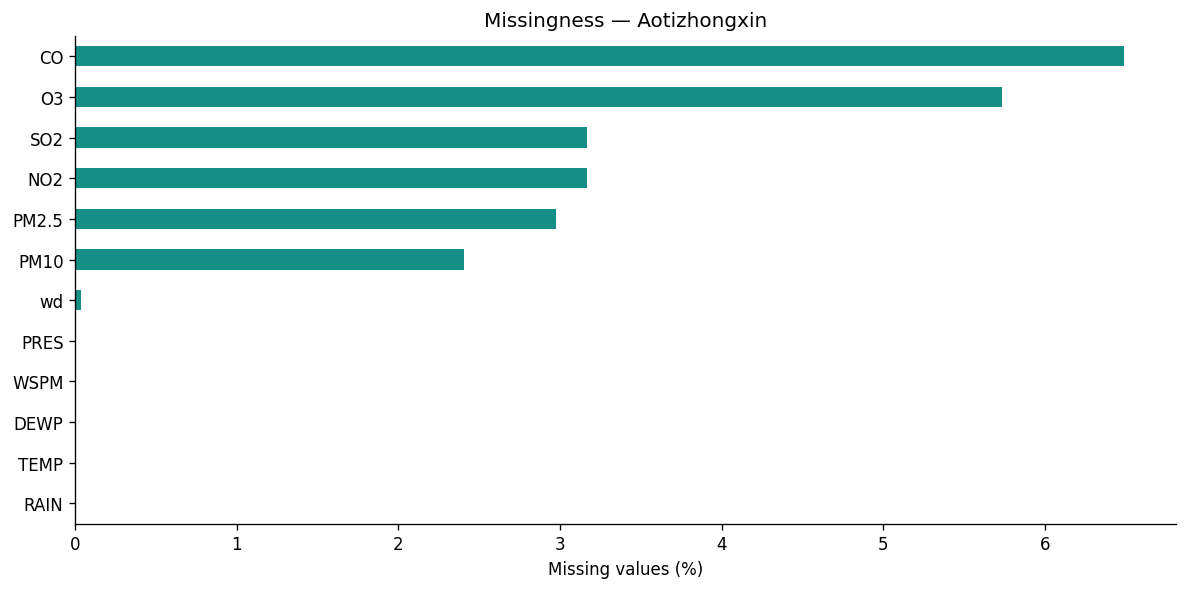

In [7]:
ax=missing[missing>0].sort_values().plot(kind='barh', figsize=(10,5), color='#168f86')
ax.set(xlabel='Missing values (%)', title='Missingness — Aotizhongxin')
plt.tight_layout(); plt.show()

**Missing-data policy:** Rows without a valid next-hour target are excluded. Missing predictors are imputed by preprocessing estimators fitted on the training partition only, avoiding information leakage from validation and test periods.

## 04 | Exploratory data analysis

Review the PM2.5 time series, its distribution, and relationships with other measured variables.

Summarize training measurements and their ranges.

In [8]:
display(explore[['PM2.5','PM10','SO2','NO2','CO','O3','TEMP','WSPM']].describe().round(2))

,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,WSPM
count,23814.00,23954.00,23767.00,23767.00,22952.0,23137.00,24542.00,24542.00
mean,83.66,114.39,19.39,62.19,1226.4,55.31,14.43,1.65
std,78.79,93.83,24.78,36.40,1094.9,58.21,10.96,1.21
min,3.00,2.00,0.29,2.00,100.0,0.21,-12.20,0.00
25%,24.00,42.00,4.00,35.00,500.0,6.00,4.70,0.90
50%,61.00,94.00,10.00,57.00,900.0,40.00,15.80,1.40
75%,116.00,161.00,24.00,84.00,1500.0,82.00,23.40,2.10
max,665.00,984.00,197.00,290.00,10000.0,423.00,40.50,11.20


Inspect the training-period daily pollution pattern.

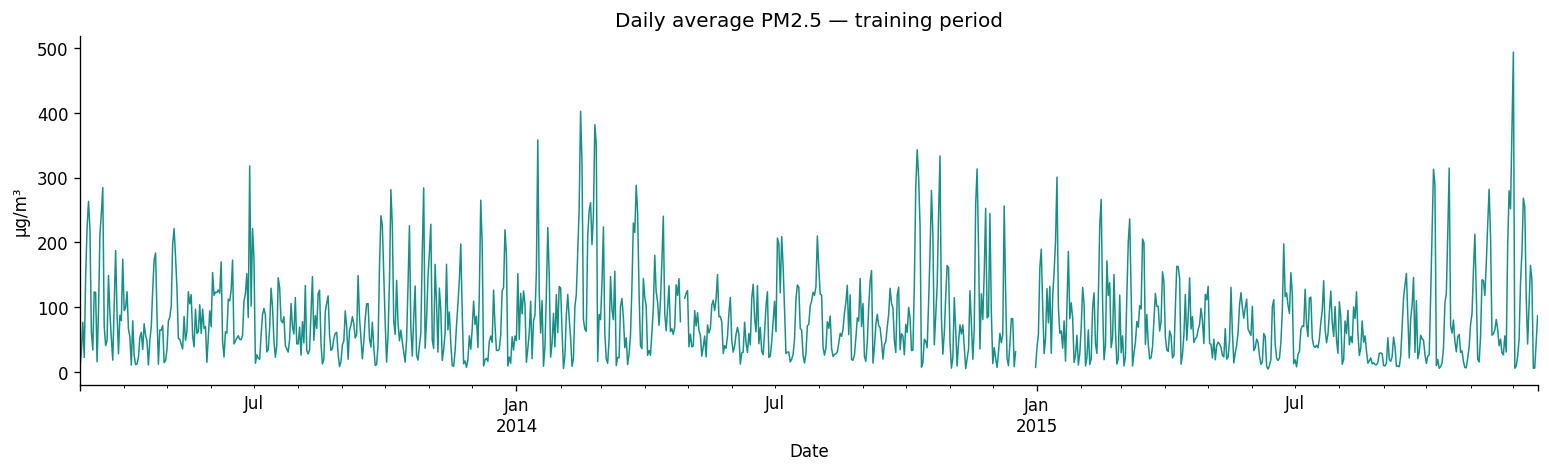

In [9]:
daily = explore.set_index('timestamp')['PM2.5'].resample('D').mean()
ax=daily.plot(figsize=(13,4), color='#168f86', lw=.9)
ax.set(title='Daily average PM2.5 — training period', ylabel='µg/m³', xlabel='Date')
plt.tight_layout();plt.show()

Inspect monthly seasonality within training.

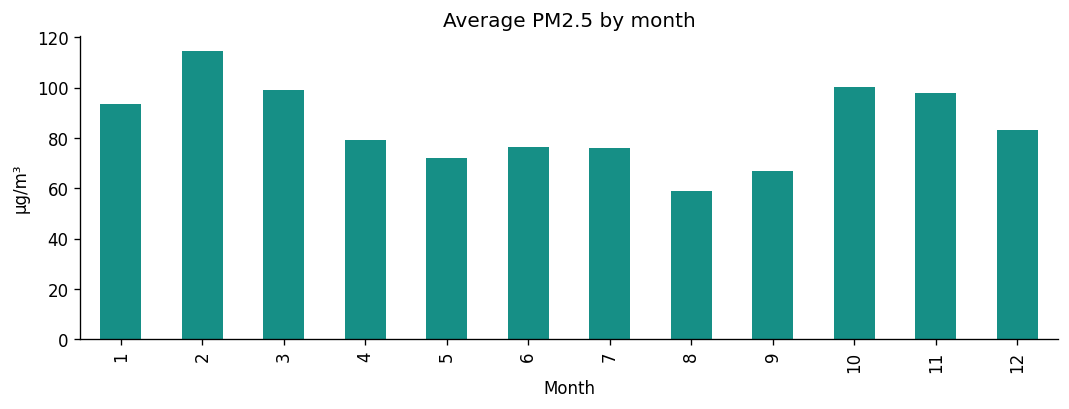

In [10]:
monthly = explore.groupby('month')['PM2.5'].mean()
ax=monthly.plot(kind='bar', figsize=(9,3.5), color='#168f86')
ax.set(title='Average PM2.5 by month', xlabel='Month',ylabel='µg/m³')
plt.tight_layout();plt.show()

Inspect the training-period daily cycle.

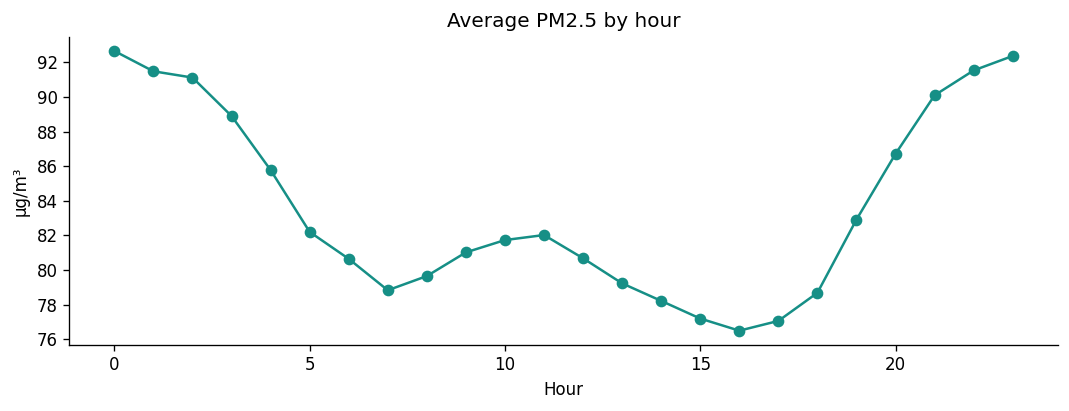

In [11]:
hourly=explore.groupby('hour')['PM2.5'].mean()
fig,ax=plt.subplots(figsize=(9,3.5))
ax.plot(hourly.index.to_numpy(), hourly.to_numpy(),marker='o',color='#168f86')
ax.set(title='Average PM2.5 by hour',xlabel='Hour',ylabel='µg/m³')
plt.tight_layout();plt.show()

Inspect pairwise training correlations without treating association as causation.

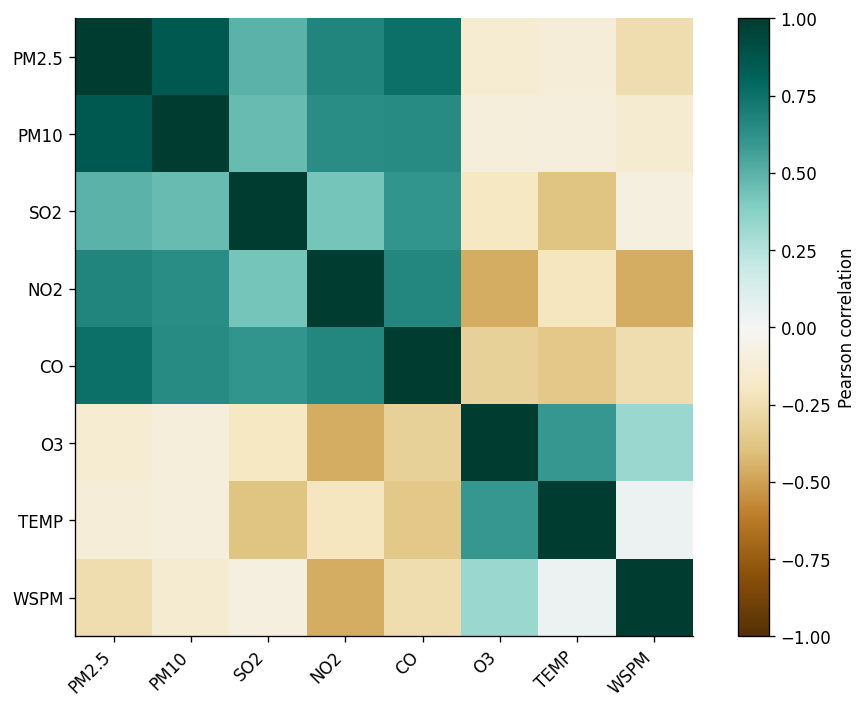

In [12]:
corr=explore[['PM2.5','PM10','SO2','NO2','CO','O3','TEMP','WSPM']].corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(corr, cmap='BrBG', vmin=-1,vmax=1)
ax.set_xticks(range(len(corr)),corr.columns,rotation=45,ha='right')
ax.set_yticks(range(len(corr)),corr.index)
fig.colorbar(im,ax=ax,label='Pearson correlation')
plt.tight_layout();plt.show()

### Training distribution, extremes and categorical counts

Training IQR upper fence: 254.0
Training observations above the fence: 1042


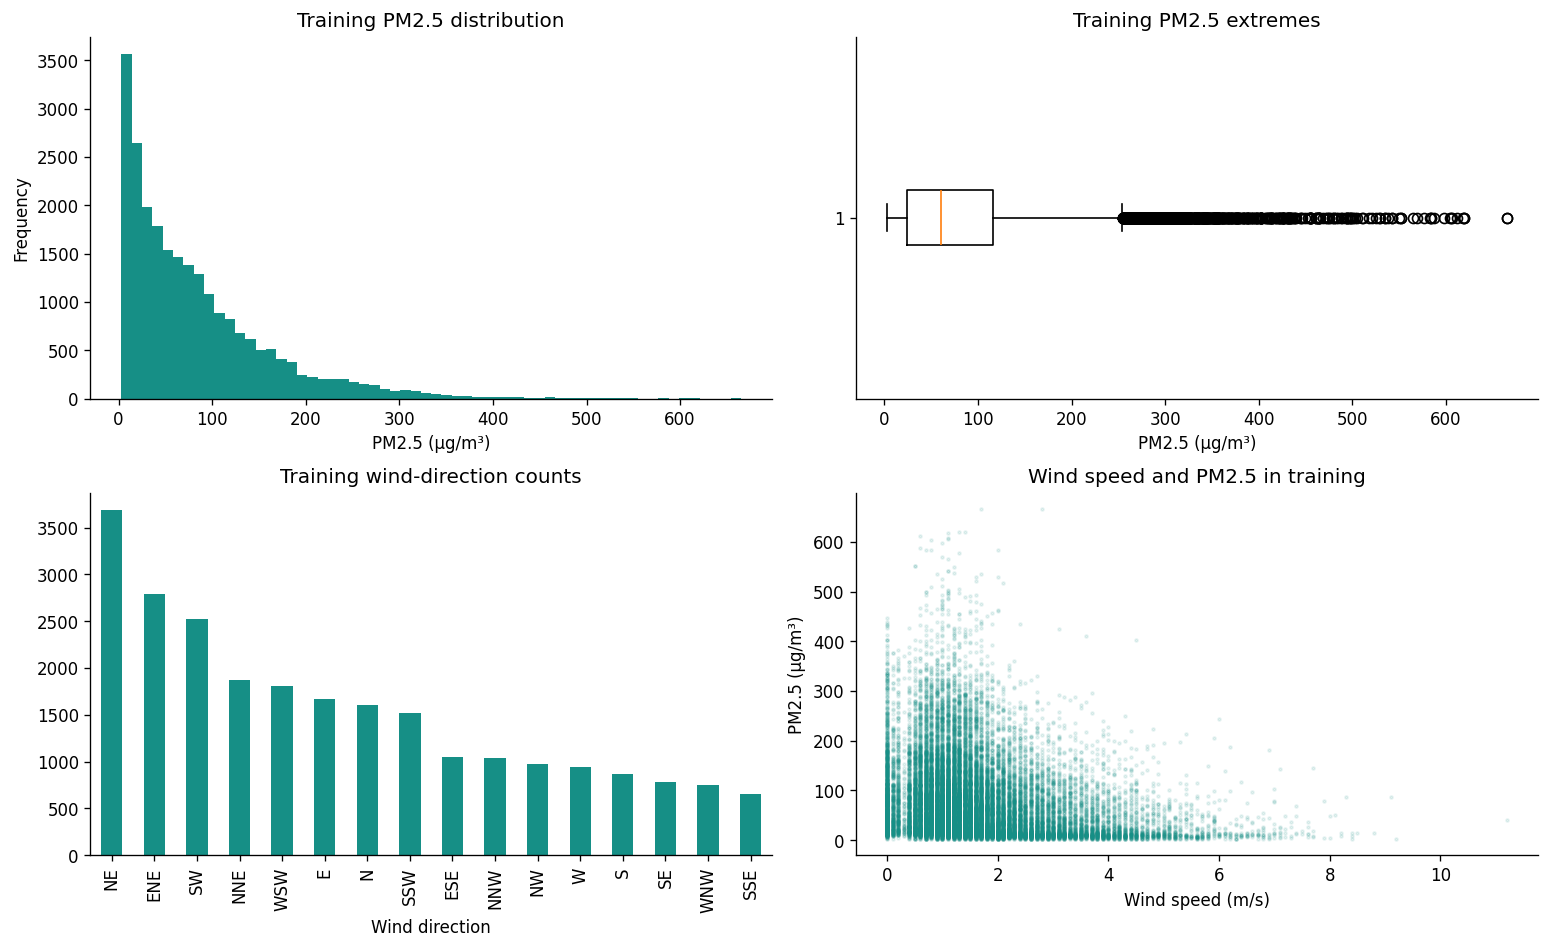

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
explore['PM2.5'].dropna().plot.hist(bins=60,ax=axes[0,0],color='#168f86')
axes[0,0].set(title='Training PM2.5 distribution',xlabel='PM2.5 (µg/m³)')
axes[0,1].boxplot(explore['PM2.5'].dropna(),vert=False)
axes[0,1].set(title='Training PM2.5 extremes',xlabel='PM2.5 (µg/m³)')
explore.wd.value_counts().plot.bar(ax=axes[1,0],color='#168f86')
axes[1,0].set(title='Training wind-direction counts',xlabel='Wind direction')
axes[1,1].scatter(explore.WSPM,explore['PM2.5'],s=3,alpha=.10,color='#168f86')
axes[1,1].set(title='Wind speed and PM2.5 in training',xlabel='Wind speed (m/s)',ylabel='PM2.5 (µg/m³)')
plt.tight_layout();plt.show()
q1,q3 = explore['PM2.5'].quantile([.25,.75])
upper_fence = float(q3+1.5*(q3-q1))
print('Training IQR upper fence:',round(upper_fence,2))
print('Training observations above the fence:',int((explore['PM2.5']>upper_fence).sum()))


### Cleaning decisions and their rationale

In [14]:
cleaning_policy = pd.DataFrame([
    ['Missing next-hour PM2.5','Exclude from supervised evaluation','An unobserved target cannot be used as a ground-truth label.'],
    ['Missing numeric predictors','Training median with missingness flags','Preserves incomplete sensor rows without learning from later partitions.'],
    ['Missing wind direction','Training most-frequent category','Produces an explicit training-fitted categorical transformation.'],
    ['High PM2.5 values','Retain without capping','Extreme pollution is part of the forecasting problem; an IQR flag alone does not prove sensor error.'],
    ['Row identifier and constant station','Exclude as predictors','Identifiers do not provide generalizable signal in this single-station experiment.'],
    ['Time components','Construct timestamps and cyclical features','Preserves temporal order and periodicity without using future values.'],
    ['Duplicate station timestamps','Require uniqueness','Conflicting observations cannot be silently discarded.'],
    ['Compound text features','Not applicable to this dataset','Unlike laptop specifications, this source uses numeric measurements and one compass category.']
],columns=['Issue','Treatment','Reason'])
display(cleaning_policy)


,Issue,Treatment,Reason
0,Missing next-hour PM2.5,Exclude from supervised evaluation,An unobserved target cannot be used as a groun...
1,Missing numeric predictors,Training median with missingness flags,Preserves incomplete sensor rows without learn...
2,Missing wind direction,Training most-frequent category,Produces an explicit training-fitted categoric...
3,High PM2.5 values,Retain without capping,Extreme pollution is part of the forecasting p...
4,Row identifier and constant station,Exclude as predictors,Identifiers do not provide generalizable signa...
5,Time components,Construct timestamps and cyclical features,Preserves temporal order and periodicity witho...
6,Duplicate station timestamps,Require uniqueness,Conflicting observations cannot be silently di...
7,Compound text features,Not applicable to this dataset,"Unlike laptop specifications, this source uses..."


**Interpretation:** Correlation describes statistical association; it does not establish a causal relationship between meteorological conditions and pollution.

## 05 | Forecast target and temporal features

Create a next-hour PM2.5 target and engineer lagged readings, historical rolling statistics, and cyclical calendar features.

Define a strictly next-hour target and past-only temporal features.

In [15]:
POLLUTANTS = ['PM2.5','PM10','SO2','NO2','CO','O3']
WEATHER = ['TEMP','PRES','DEWP','RAIN','WSPM']

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Only same-hour measurements and historical PM2.5 may predict next hour."""
    x = df.copy().sort_values(['station','timestamp'])
    # Forecast target exists only when the next station reading is exactly one hour later.
    group = x.groupby('station', sort=False)
    # Causal persistence: latest observed PM2.5 at or before forecast origin.
    x['persistence_pm25'] = group['PM2.5'].ffill()
    next_time = group['timestamp'].shift(-1)
    x['target_timestamp'] = next_time
    x['target_next_hour'] = group['PM2.5'].shift(-1)
    x.loc[(next_time-x['timestamp']) != pd.Timedelta(hours=1),'target_next_hour'] = np.nan
    for lag in [1,3,6,24]:
        lag_time = group['timestamp'].shift(lag)
        x[f'pm25_lag_{lag}'] = group['PM2.5'].shift(lag).where((x['timestamp']-lag_time)==pd.Timedelta(hours=lag))
    # Shift one step: rolling statistics never incorporate the forecast target.
    for window in [3,6,24]:
        x[f'pm25_past_{window}h_mean'] = x.groupby('station',sort=False)['PM2.5'].transform(
            lambda s: s.shift(1).rolling(window,min_periods=window).mean())
        first_time = group['timestamp'].shift(window)
        x[f'pm25_past_{window}h_mean'] = x[f'pm25_past_{window}h_mean'].where(
            (x['timestamp'] - first_time) == pd.Timedelta(hours=window))
    x['hour_sin'] = np.sin(2*np.pi*x['hour']/24)
    x['hour_cos'] = np.cos(2*np.pi*x['hour']/24)
    x['month_sin'] = np.sin(2*np.pi*(x['month']-1)/12)
    x['month_cos'] = np.cos(2*np.pi*(x['month']-1)/12)
    return x.dropna(subset=['target_next_hour','persistence_pm25']).reset_index(drop=True)

df = engineer_features(raw)
print('Raw observations:', len(raw), '| Eligible forecast origins:', len(df))
display(df[['timestamp','target_timestamp','PM2.5','target_next_hour','persistence_pm25']].head(8))
assert (df.target_timestamp - df.timestamp).eq(pd.Timedelta(hours=1)).all()


Raw observations: 35064 | Eligible forecast origins: 34138


,timestamp,target_timestamp,PM2.5,target_next_hour,persistence_pm25
0,2013-03-01 00:00:00,2013-03-01 01:00:00,4.0,8.0,4.0
1,2013-03-01 01:00:00,2013-03-01 02:00:00,8.0,7.0,8.0
2,2013-03-01 02:00:00,2013-03-01 03:00:00,7.0,6.0,7.0
3,2013-03-01 03:00:00,2013-03-01 04:00:00,6.0,3.0,6.0
4,2013-03-01 04:00:00,2013-03-01 05:00:00,3.0,5.0,3.0
5,2013-03-01 05:00:00,2013-03-01 06:00:00,5.0,3.0,5.0
6,2013-03-01 06:00:00,2013-03-01 07:00:00,3.0,3.0,3.0
7,2013-03-01 07:00:00,2013-03-01 08:00:00,3.0,3.0,3.0


Inspect lag and rolling-window values on early observations.

In [16]:
lag_cols=['pm25_lag_1','pm25_lag_3','pm25_lag_6','pm25_lag_24',
          'pm25_past_3h_mean','pm25_past_6h_mean','pm25_past_24h_mean']
display(df[['timestamp','PM2.5',*lag_cols]].head(30).tail(10))
print('Temporal features:',lag_cols)

Temporal features: ['pm25_lag_1', 'pm25_lag_3', 'pm25_lag_6', 'pm25_lag_24', 'pm25_past_3h_mean', 'pm25_past_6h_mean', 'pm25_past_24h_mean']


,timestamp,PM2.5,pm25_lag_1,pm25_lag_3,pm25_lag_6,pm25_lag_24,pm25_past_3h_mean,pm25_past_6h_mean,pm25_past_24h_mean
20,2013-03-01 20:00:00,11.0,8.0,10.0,6.0,NaN,9.666667,8.666667,NaN
21,2013-03-01 21:00:00,12.0,11.0,11.0,8.0,NaN,10.000000,9.500000,NaN
22,2013-03-01 22:00:00,15.0,12.0,8.0,9.0,NaN,10.333333,10.166667,NaN
23,2013-03-01 23:00:00,24.0,15.0,11.0,10.0,NaN,12.666667,11.166667,NaN
24,2013-03-02 00:00:00,22.0,24.0,12.0,11.0,4.0,17.000000,13.500000,7.125
25,2013-03-02 01:00:00,14.0,22.0,15.0,8.0,8.0,20.333333,15.333333,7.875
26,2013-03-02 02:00:00,13.0,14.0,24.0,11.0,7.0,20.000000,16.333333,8.125
27,2013-03-02 03:00:00,3.0,13.0,22.0,12.0,6.0,16.333333,16.666667,8.375
28,2013-03-02 04:00:00,3.0,3.0,14.0,15.0,3.0,10.000000,15.166667,8.250
29,2013-03-02 05:00:00,9.0,3.0,13.0,24.0,5.0,6.333333,13.166667,8.250


Inspect cyclical time encodings.

In [17]:
display(df[['hour','hour_sin','hour_cos','month','month_sin','month_cos']].head())
print('Cyclical encoding preserves proximity between hour 23 and hour 0 and between December and January.')

Cyclical encoding preserves proximity between hour 23 and hour 0 and between December and January.


,hour,hour_sin,hour_cos,month,month_sin,month_cos
0,0,0.000000,1.000000,3,0.866025,0.5
1,1,0.258819,0.965926,3,0.866025,0.5
2,2,0.500000,0.866025,3,0.866025,0.5
3,3,0.707107,0.707107,3,0.866025,0.5
4,4,0.866025,0.500000,3,0.866025,0.5


**Temporal integrity:** Predictors use observations available at the forecast origin. Lagged and rolling features do not include the next-hour target.

## 06 | Chronological train / validation / test split

Preserve time order to evaluate generalization to observations later than those used for fitting.
A one-hour boundary purge keeps target observations strictly before the following partition. Nominal proportions are 70/15/15 before purging.


Apply the fixed chronological boundaries and exclude overlapping target timestamps.

In [18]:
def temporal_split(df: pd.DataFrame):
    """Global timestamp cutoffs avoid simultaneous station rows leaking across splits."""
    unique = np.sort(df['timestamp'].unique())
    if len(unique) < 100:
        raise ValueError('Not enough hourly timestamps for robust temporal splitting.')
    train_cut = TRAIN_CUTOFF
    val_cut = TEST_CUTOFF
    train = df[(df.timestamp < train_cut) & (df.target_timestamp < train_cut)].copy()
    val = df[(df.timestamp >= train_cut)&(df.timestamp < val_cut)&(df.target_timestamp < val_cut)].copy()
    test = df[df.timestamp >= val_cut].copy()
    assert train.timestamp.max() < val.timestamp.min() <= val.timestamp.max() < test.timestamp.min()
    return train,val,test

train, val, test = temporal_split(df)
summary = pd.DataFrame({
    'Partition': ['Train', 'Validation', 'Test'],
    'Rows': [len(train), len(val), len(test)],
    'First origin': [part.timestamp.min() for part in [train,val,test]],
    'Last origin': [part.timestamp.max() for part in [train,val,test]],
    'Last target': [part.target_timestamp.max() for part in [train,val,test]]
})
display(summary)
assert train.target_timestamp.max() < val.timestamp.min()
assert val.target_timestamp.max() < test.timestamp.min()
print('Boundary rows excluded:', len(df) - len(train) - len(val) - len(test))


Boundary rows excluded: 2


,Partition,Rows,First origin,Last origin,Last target
0,Train,23813,2013-03-01 00:00:00,2015-12-18 14:00:00,2015-12-18 15:00:00
1,Validation,5151,2015-12-18 16:00:00,2016-07-24 18:00:00,2016-07-24 19:00:00
2,Test,5172,2016-07-24 20:00:00,2017-02-28 22:00:00,2017-02-28 23:00:00


Visualize the partition sizes after boundary exclusions.

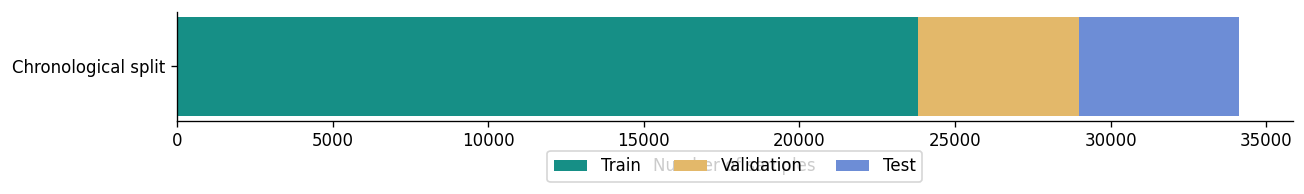

In [19]:
fig,ax=plt.subplots(figsize=(11,1.8))
ax.barh(['Chronological split'],[len(train)],color='#168f86',label='Train')
ax.barh(['Chronological split'],[len(val)],left=[len(train)],color='#e3b86a',label='Validation')
ax.barh(['Chronological split'],[len(test)],left=[len(train)+len(val)],color='#6d8dd6',label='Test')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.2),ncol=3)
ax.set_xlabel('Number of samples');plt.tight_layout();plt.show()

## 07 | Preprocessing pipeline

Define numeric and categorical transformations, including training-only imputation and categorical encoding.

Define the predictor list and separate predictors from target labels.

In [20]:
def features(df):
    candidates = ['PM2.5',*POLLUTANTS[1:],*WEATHER,'wd',
                  'pm25_lag_1','pm25_lag_3','pm25_lag_6','pm25_lag_24',
                  'pm25_past_3h_mean','pm25_past_6h_mean','pm25_past_24h_mean',
                  'hour_sin','hour_cos','month_sin','month_cos']
    return [c for c in candidates if c in df.columns]

cols = features(df)
xtr, ytr = train[cols], train['target_next_hour']
xval, yval = val[cols], val['target_next_hour']
xte, yte = test[cols], test['target_next_hour']
assert 'target_next_hour' not in cols and 'target_timestamp' not in cols
print('Predictor count:', len(cols))
print(cols)
print('Training matrix:', xtr.shape)


Predictor count: 23
['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'wd', 'pm25_lag_1', 'pm25_lag_3', 'pm25_lag_6', 'pm25_lag_24', 'pm25_past_3h_mean', 'pm25_past_6h_mean', 'pm25_past_24h_mean', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']
Training matrix: (23813, 23)


Define preprocessing that learns imputation, encoding and scaling only during training.

In [21]:
def preprocessor(cols):
    cat = [c for c in ['station','wd'] if c in cols]
    num = [c for c in cols if c not in cat]
    return ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),
                             ('scale',StandardScaler())]),num),
        ('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                                 ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)
    ],sparse_threshold=0)

prep = preprocessor(cols)
display(prep)


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name

### Training target skewness and transformation assessment

Target transformations are compared using validation MAE in the original concentration units.


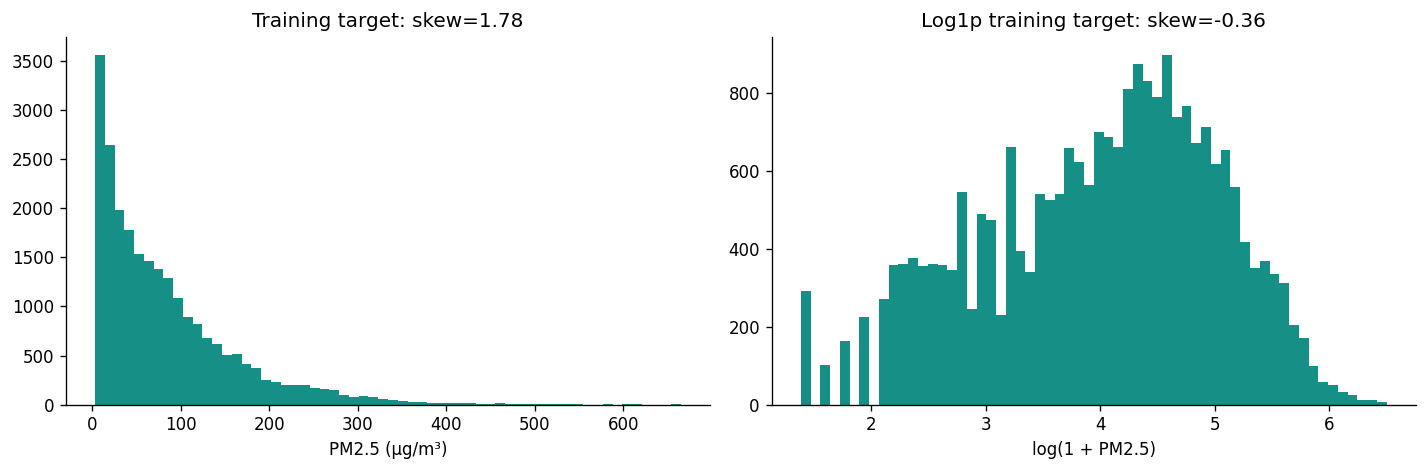

In [22]:
target_skew = float(ytr.skew())
log_skew = float(np.log1p(ytr).skew())
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(ytr,bins=60,color='#168f86');axes[0].set(title=f'Training target: skew={target_skew:.2f}',xlabel='PM2.5 (µg/m³)')
axes[1].hist(np.log1p(ytr),bins=60,color='#168f86');axes[1].set(title=f'Log1p training target: skew={log_skew:.2f}',xlabel='log(1 + PM2.5)')
plt.tight_layout();plt.show()
print('Target transformations are compared using validation MAE in the original concentration units.')


## 08 | Persistence baseline

Use the current PM2.5 reading as the forecast for the next hour. This non-trained benchmark provides a strong reference for short-horizon prediction.

Evaluate the persistence benchmark on validation data.

In [23]:
def scores(y, pred):
    return {'MAE':float(mean_absolute_error(y,pred)),
            'RMSE':float(np.sqrt(mean_squared_error(y,pred))),
            'R2':float(r2_score(y,pred))}

results = {'persistence': {'validation': scores(yval, val['persistence_pm25'])}}
display(pd.DataFrame(results['persistence']).T.round(3))


,MAE,RMSE,R2
validation,10.313,21.044,0.938


## 09 | Linear regression

Fit a linear model and evaluate its predictions on the separate validation period.

Fit a linear regression baseline and measure validation error.

In [24]:
linear=Pipeline([('prep',preprocessor(cols)),('model',LinearRegression())])
linear.fit(xtr,ytr)
results['linear_regression']={'validation':scores(yval,linear.predict(xval))}
display(pd.DataFrame(results['linear_regression']).T.round(3))

,MAE,RMSE,R2
validation,10.795,20.305,0.942


## 10 | Histogram gradient boosting

Fit a nonlinear tree-based ensemble and evaluate its validation error.

Fit a nonlinear boosting model and measure validation error.

In [25]:
boost=Pipeline([('prep',preprocessor(cols)),('model',
    HistGradientBoostingRegressor(max_iter=120,max_leaf_nodes=15,learning_rate=.08,random_state=42,early_stopping=False))])
boost.fit(xtr,ytr)
results['hist_gradient_boosting']={'validation':scores(yval,boost.predict(xval))}
display(pd.DataFrame(results['hist_gradient_boosting']).T.round(3))

,MAE,RMSE,R2
validation,10.243,20.739,0.94


## 11 | Hyperparameter optimization

Evaluate six sampled configurations with three-fold time-series cross-validation within the training partition. Model selection remains based on the separate validation MAE.
A one-row CV gap separates training targets from validation origins. Random internal early stopping is disabled.


Tune boosting using time-series cross-validation within training only.

In [26]:
cv_data=train.sort_values('timestamp')
search_model=Pipeline([('prep',preprocessor(cols)),('model',HistGradientBoostingRegressor(random_state=42,early_stopping=False))])
param_grid={'model__max_iter':[80,120,160], 'model__learning_rate':[.04,.08,.12],
            'model__max_leaf_nodes':[15,31], 'model__min_samples_leaf':[20,40]}
search=RandomizedSearchCV(search_model,param_grid,n_iter=6,cv=TimeSeriesSplit(n_splits=3,gap=1),
    scoring='neg_mean_absolute_error',random_state=42,n_jobs=1,refit=True)
print('Starting temporal search...')
search.fit(cv_data[cols],cv_data['target_next_hour'])
print('Best parameters:',search.best_params_)
print('Mean CV MAE:',round(-search.best_score_,3))

Starting temporal search...
Best parameters: {'model__min_samples_leaf': 40, 'model__max_leaf_nodes': 15, 'model__max_iter': 80, 'model__learning_rate': 0.08}
Mean CV MAE: 11.226


Fit the tuned model on training and evaluate validation performance.

In [27]:
tuned=Pipeline([('prep',preprocessor(cols)),('model',HistGradientBoostingRegressor(
    max_iter=search.best_params_['model__max_iter'],
    learning_rate=search.best_params_['model__learning_rate'],
    max_leaf_nodes=search.best_params_['model__max_leaf_nodes'],
    min_samples_leaf=search.best_params_['model__min_samples_leaf'],random_state=42,early_stopping=False))])
tuned.fit(xtr,ytr)
results['tuned_boosting']={'validation':scores(yval,tuned.predict(xval))}
display(pd.DataFrame(results['tuned_boosting']).T.round(3))

,MAE,RMSE,R2
validation,10.256,20.532,0.941


### Log-transformed target candidate

In [28]:
log_boost = TransformedTargetRegressor(
    regressor=Pipeline([('prep',preprocessor(cols)),('model',HistGradientBoostingRegressor(
        max_iter=120,max_leaf_nodes=15,learning_rate=.08,random_state=42,early_stopping=False))]),
    func=np.log1p,inverse_func=np.expm1)
log_boost.fit(xtr,ytr)
results['log_target_boosting']={'validation':scores(yval,log_boost.predict(xval))}
display(pd.DataFrame(results['log_target_boosting']).T.round(3))


,MAE,RMSE,R2
validation,10.554,22.236,0.931


## 12 | Validation comparison and model selection

Select the candidate with the lowest validation mean absolute error before inspecting final test performance.

Select the learned model using validation MAE and document the target-transformation decision.

In [29]:
fitted={'linear_regression':linear,'hist_gradient_boosting':boost,'tuned_boosting':tuned,'log_target_boosting':log_boost}
val_compare=pd.DataFrame({name:results[name]['validation'] for name in results}).T.sort_values('MAE')
display(val_compare.round(3))
selected=min(fitted,key=lambda name:results[name]['validation']['MAE'])
print('Selected by validation MAE:',selected)
transformation_decision = (
    'Use log1p target transformation: the log-target model achieved the lowest validation MAE.'
    if selected == 'log_target_boosting' else
    'Keep the target in original units: the log-target candidate did not achieve the lowest validation MAE.'
)
print(transformation_decision)


Selected by validation MAE: hist_gradient_boosting
Keep the target in original units: the log-target candidate did not achieve the lowest validation MAE.


,MAE,RMSE,R2
hist_gradient_boosting,10.243,20.739,0.940
tuned_boosting,10.256,20.532,0.941
persistence,10.313,21.044,0.938
log_target_boosting,10.554,22.236,0.931
linear_regression,10.795,20.305,0.942


### Feature importance on the validation partition

Top three predictors: PM2.5, PM10, pm25_lag_1


,feature,mae_increase,repeat_std
0,PM2.5,58.609,0.622
1,PM10,3.974,0.231
2,pm25_lag_1,2.864,0.113
3,WSPM,2.262,0.119
4,DEWP,1.616,0.063
5,NO2,1.349,0.040
6,pm25_past_3h_mean,1.214,0.011
7,CO,1.209,0.075
8,hour_sin,1.169,0.025
9,wd,1.154,0.045


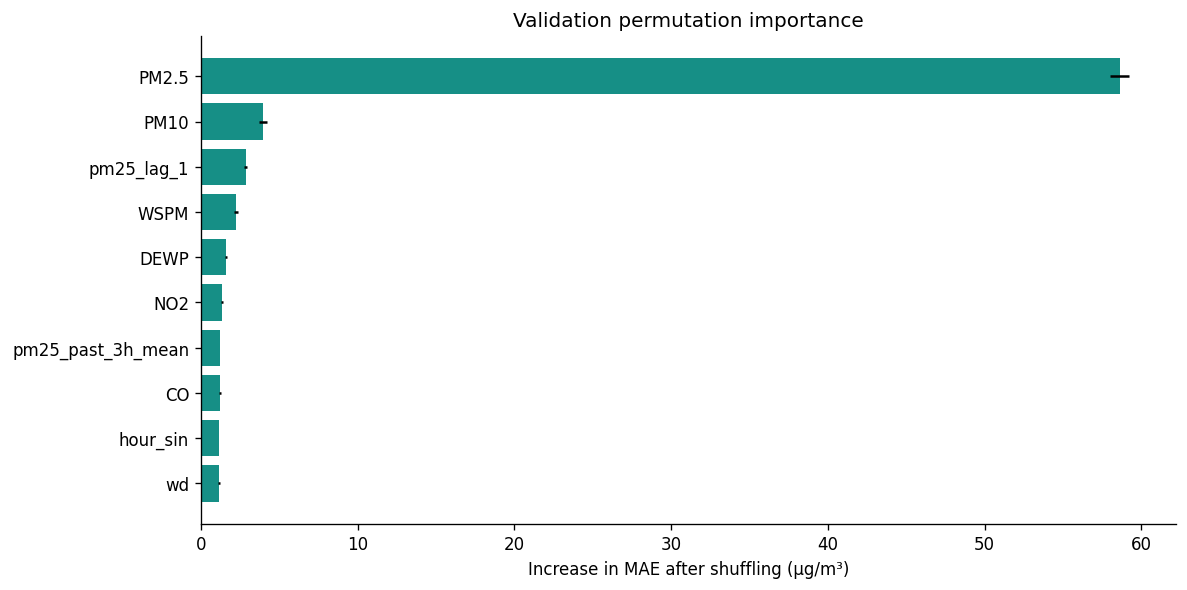

In [30]:
importance_result = permutation_importance(
    fitted[selected], xval, yval, scoring='neg_mean_absolute_error',
    n_repeats=4,random_state=42,n_jobs=1,max_samples=1200)
importance_table = pd.DataFrame({
    'feature':cols,'mae_increase':importance_result.importances_mean,
    'repeat_std':importance_result.importances_std
}).sort_values('mae_increase',ascending=False).reset_index(drop=True)
top_features = importance_table.head(3)['feature'].tolist()
display(importance_table.round(3))
plot=importance_table.head(10).iloc[::-1]
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(plot.feature,plot.mae_increase,xerr=plot.repeat_std,color='#168f86')
ax.set(title='Validation permutation importance',xlabel='Increase in MAE after shuffling (µg/m³)')
plt.tight_layout();plt.show()
print('Top three predictors:', ', '.join(top_features))


## 13 | Holdout test evaluation

Compare all candidates on the untouched, chronologically latest test period.

Evaluate the frozen candidates on the chronological holdout test.

In [31]:
results['persistence']['test'] = scores(yte, test['persistence_pm25'])
for name,model in fitted.items():
    results[name]['test']=scores(yte,model.predict(xte))
test_compare=pd.DataFrame({name:results[name]['test'] for name in results}).T
comparison=pd.DataFrame({'Validation MAE':{k:v['validation']['MAE'] for k,v in results.items()},
                         'Test MAE':{k:v['test']['MAE'] for k,v in results.items()},
                         'Test RMSE':{k:v['test']['RMSE'] for k,v in results.items()},
                         'Test R2':{k:v['test']['R2'] for k,v in results.items()}})
display(comparison.round(3))

,Validation MAE,Test MAE,Test RMSE,Test R2
persistence,10.313,11.069,20.937,0.950
linear_regression,10.795,11.237,20.264,0.953
hist_gradient_boosting,10.243,10.788,20.761,0.951
tuned_boosting,10.256,10.880,20.730,0.951
log_target_boosting,10.554,11.344,22.240,0.943


Compare final test MAE across models.

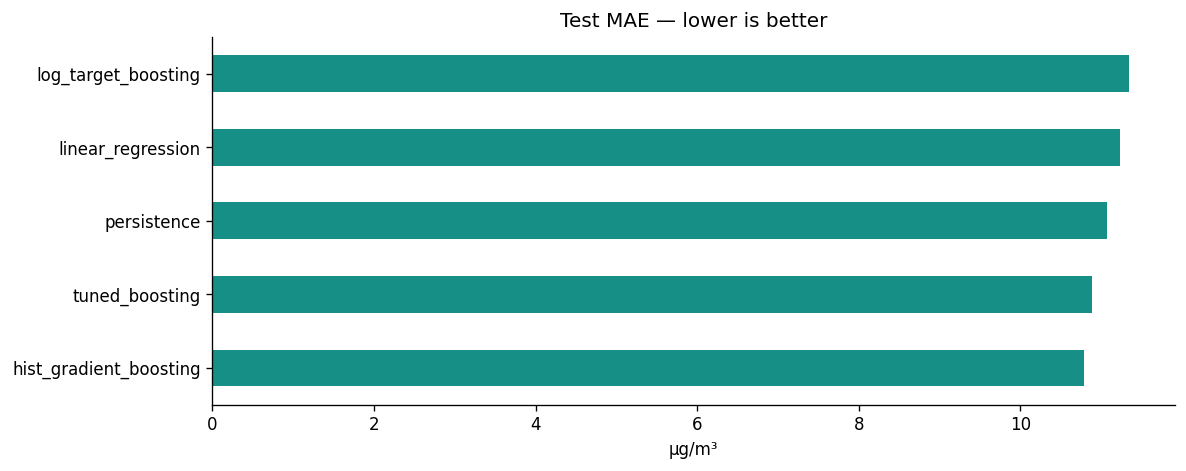

In [32]:
ax=comparison['Test MAE'].sort_values().plot(kind='barh',figsize=(10,4),color='#168f86')
ax.set(title='Test MAE — lower is better',xlabel='µg/m³')
plt.tight_layout();plt.show()

## 14 | Evaluation metrics

- **MAE (µg/m³):** Mean absolute prediction error; lower is better.
- **RMSE (µg/m³):** Root mean squared error; penalizes large deviations more strongly.
- **R²:** Coefficient of determination; it is not a percentage classification accuracy.

Compute the selected model’s improvement over persistence.

In [33]:
winner=results[selected]['test'];baseline=results['persistence']['test']
improvement=(baseline['MAE']-winner['MAE'])/baseline['MAE']*100
print('Model:',selected)
print('MAE:',round(winner['MAE'],3),'| RMSE:',round(winner['RMSE'],3),'| R²:',round(winner['R2'],4))
print('MAE improvement over persistence:',round(improvement,2),'%')

Model: hist_gradient_boosting
MAE: 10.788 | RMSE: 20.761 | R²: 0.9506
MAE improvement over persistence: 2.54 %


## 15 | Forecast diagnostics

Inspect observed versus predicted PM2.5, residual patterns, and error distribution on the test partition.

Inspect saved test predictions and their absolute errors.

In [34]:
pred = fitted[selected].predict(xte)
view = test[['timestamp','target_timestamp','station','target_next_hour','persistence_pm25']].copy()
view['prediction'] = pred
view['absolute_error'] = abs(view.target_next_hour - view.prediction)
display(view.head(12).round(2))


,timestamp,target_timestamp,station,target_next_hour,persistence_pm25,prediction,absolute_error
28966,2016-07-24 20:00:00,2016-07-24 21:00:00,Aotizhongxin,73.0,66.0,63.26,9.74
28967,2016-07-24 21:00:00,2016-07-24 22:00:00,Aotizhongxin,82.0,73.0,72.99,9.01
28968,2016-07-24 22:00:00,2016-07-24 23:00:00,Aotizhongxin,73.0,82.0,84.94,11.94
28969,2016-07-24 23:00:00,2016-07-25 00:00:00,Aotizhongxin,55.0,73.0,75.69,20.69
28970,2016-07-25 00:00:00,2016-07-25 01:00:00,Aotizhongxin,65.0,55.0,56.30,8.70
28971,2016-07-25 01:00:00,2016-07-25 02:00:00,Aotizhongxin,51.0,65.0,68.38,17.38
28972,2016-07-25 02:00:00,2016-07-25 03:00:00,Aotizhongxin,51.0,51.0,53.04,2.04
28973,2016-07-25 03:00:00,2016-07-25 04:00:00,Aotizhongxin,48.0,51.0,49.60,1.60
28974,2016-07-25 04:00:00,2016-07-25 05:00:00,Aotizhongxin,55.0,48.0,47.16,7.84
28975,2016-07-25 05:00:00,2016-07-25 06:00:00,Aotizhongxin,59.0,55.0,56.25,2.75


Plot predicted and observed concentrations at the target timestamps.

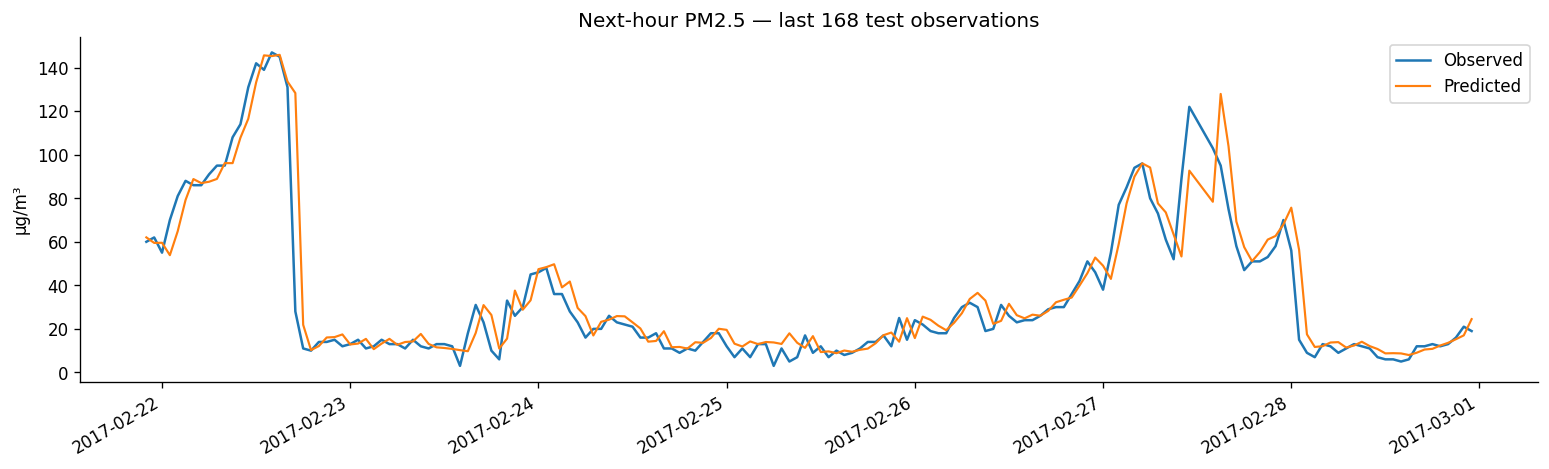

In [35]:
recent=view.tail(168)
fig,ax=plt.subplots(figsize=(13,4))
ax.plot(recent.target_timestamp,recent.target_next_hour,label='Observed',lw=1.5)
ax.plot(recent.target_timestamp,recent.prediction,label='Predicted',lw=1.3)
ax.set(title='Next-hour PM2.5 — last 168 test observations',ylabel='µg/m³')
ax.legend();fig.autofmt_xdate();plt.tight_layout();plt.show()

Compare predictions with observations; the view clips to the 99th percentile for readability.

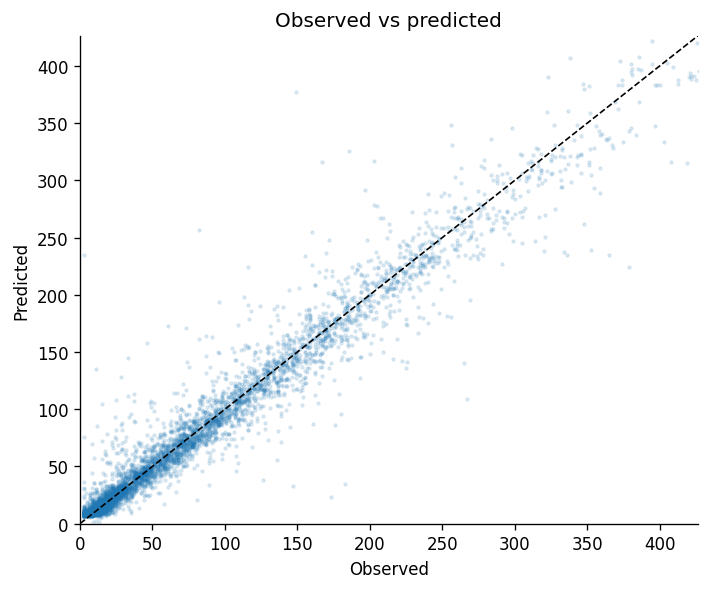

In [36]:
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter(view.target_next_hour,view.prediction,s=3,alpha=.13)
lim=max(float(view.target_next_hour.quantile(.99)),float(view.prediction.quantile(.99)))
ax.plot([0,lim],[0,lim],'k--',lw=1)
ax.set(xlabel='Observed',ylabel='Predicted',title='Observed vs predicted',xlim=(0,lim),ylim=(0,lim))
plt.tight_layout();plt.show()

Inspect the distribution of test absolute errors.

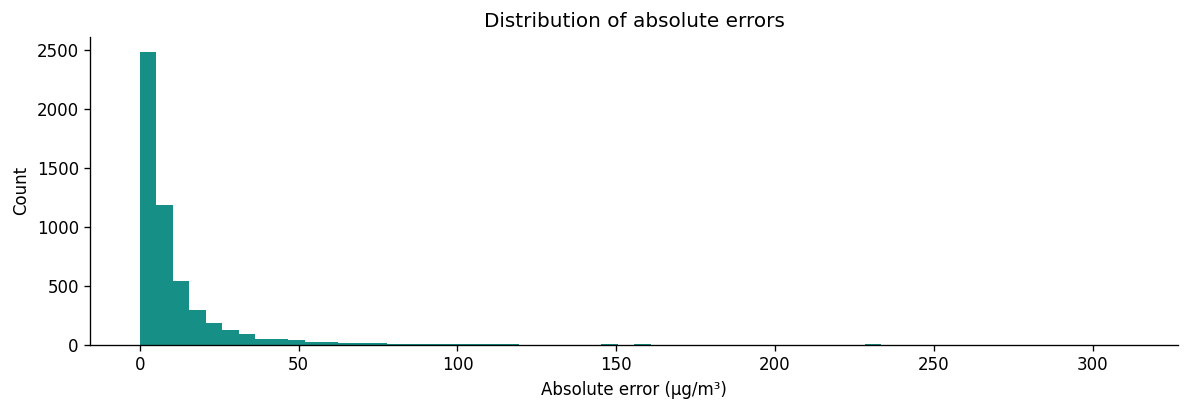

In [37]:
fig,ax=plt.subplots(figsize=(10,3.5))
ax.hist(view.absolute_error,bins=60,color='#168f86')
ax.set(title='Distribution of absolute errors',xlabel='Absolute error (µg/m³)',ylabel='Count')
plt.tight_layout();plt.show()

Inspect large errors and a high-concentration subset defined by a training threshold.

In [38]:
print('Median absolute error:',round(view.absolute_error.median(),2))
print('90th percentile absolute error:',round(view.absolute_error.quantile(.90),2))
print('Largest five test errors:')
display(view.nlargest(5,'absolute_error').round(2))
# Training-derived threshold avoids choosing an event threshold from test outcomes.
high_threshold = float(ytr.quantile(0.90))
high = view.target_next_hour >= high_threshold
high_metrics = {
    'threshold': high_threshold,
    'test_observations': int(high.sum()),
    'model_mae': float(view.loc[high, 'absolute_error'].mean()),
    'persistence_mae': float(abs(view.loc[high, 'target_next_hour'] - view.loc[high, 'persistence_pm25']).mean())
}
display(pd.Series(high_metrics, name='High-concentration diagnostics'))


Median absolute error: 5.45
90th percentile absolute error: 24.92
Largest five test errors:


,timestamp,target_timestamp,station,target_next_hour,persistence_pm25,prediction,absolute_error
33386,2017-01-28 00:00:00,2017-01-28 01:00:00,Aotizhongxin,576.0,305.0,264.75,311.25
33391,2017-01-28 05:00:00,2017-01-28 06:00:00,Aotizhongxin,697.0,713.0,445.11,251.89
32766,2017-01-02 03:00:00,2017-01-02 04:00:00,Aotizhongxin,211.0,429.0,447.76,236.76
33390,2017-01-28 04:00:00,2017-01-28 05:00:00,Aotizhongxin,713.0,682.0,479.97,233.03
33830,2017-02-15 13:00:00,2017-02-15 14:00:00,Aotizhongxin,3.0,229.0,234.68,231.68


threshold            187.000000
test_observations    681.000000
model_mae             24.204365
persistence_mae       22.196769
Name: High-concentration diagnostics, dtype: float64

## 16 | Model and evaluation artifacts

The saved estimator contains training-fitted preprocessing and the selected regression model. A shared JSON summary supplies the application metrics. The prediction export records both forecast-origin and target timestamps for every test observation.


Save the trained model and matching metrics and predictions.

In [39]:
bundle = {'model': fitted[selected], 'features': cols, 'selected': selected,
          'station': 'Aotizhongxin', 'sklearn_version': sklearn.__version__}
joblib.dump(bundle, OUTPUT / 'model.joblib')
report = {
    'source': 'https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data',
    'station': 'Aotizhongxin', 'raw_rows': len(raw), 'usable_rows': len(df),
    'target': 'PM2.5 at forecast origin plus one hour (µg/m³)',
    'splits': {'train': len(train), 'validation': len(val), 'test': len(test),
               'test_start': str(test.timestamp.min()), 'test_end': str(test.timestamp.max())},
    'selected_model': selected, 'results': results,
    'tuning': {'best_params': search.best_params_, 'cv_mae': float(-search.best_score_)},
    'target_skew':target_skew,'log_target_skew':log_skew,
    'transformation_decision':transformation_decision,
    'feature_importance':importance_table.to_dict(orient='records'),
    'top_features':top_features,
    'improvement_pct': float(improvement), 'high_concentration': high_metrics,
    'environment': {'python': platform.python_version(), 'scikit_learn': sklearn.__version__}
}
(OUTPUT / 'metrics.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
view.to_csv(OUTPUT / 'predictions.csv', index=False)
print('Saved model.joblib, metrics.json and predictions.csv')


Saved model.joblib, metrics.json and predictions.csv


Verify that the persisted metrics describe the selected model.

In [40]:
saved_report = json.loads((OUTPUT / 'metrics.json').read_text())
assert saved_report['selected_model'] == selected
assert saved_report['results'][selected]['test'] == winner
display(comparison.round(3))


,Validation MAE,Test MAE,Test RMSE,Test R2
persistence,10.313,11.069,20.937,0.950
linear_regression,10.795,11.237,20.264,0.953
hist_gradient_boosting,10.243,10.788,20.761,0.951
tuned_boosting,10.256,10.880,20.730,0.951
log_target_boosting,10.554,11.344,22.240,0.943


## 17 | Conclusions and recommendations

Summarize the experimental results, limitations, and potential extensions.

Summarize data issues, methods, measured findings and operational limitations.

In [41]:
model_table = '| Model | Validation MAE | Test MAE | Test RMSE | Test R² |\n|---|---:|---:|---:|---:|\n'
for name, values in results.items():
    model_table += f"| {name} | {values['validation']['MAE']:.3f} | {values['test']['MAE']:.3f} | {values['test']['RMSE']:.3f} | {values['test']['R2']:.4f} |\n"
biggest_missing = column_audit['missing_count'].idxmax()
summary = f"""# RASD: Next-Hour Air Quality Forecasting

## Objective and source
Predict next-hour PM2.5 from measurements available at the forecast origin.
Source: Chen, S. (2017), UCI Beijing Multi-Site Air Quality, DOI 10.24432/C5RK5G, CC BY 4.0.
The original Aotizhongxin station file contains {len(raw):,} observations from March 2013 to February 2017.

## Audit and cleaning
Every source column is inspected in the notebook for type, missingness, cardinality and predictive role.
All exploratory decisions use the training period only. Duplicate timestamps and invalid negative sensor values are checked explicitly.
The most incomplete training column is {biggest_missing}, with {int(column_audit.loc[biggest_missing,'missing_count']):,} missing values.
Missing numeric predictors use training medians with missingness flags. Wind direction uses training-fitted categorical imputation and encoding.
Missing targets are excluded. Pollution extremes remain because large values can be real events.
The row index and constant station label are excluded from predictors.
The source contains no combined free-text specification columns, so text-component extraction is not applicable.

## Features and chronology
Inputs include current sensor readings, historical lags, shifted rolling means and cyclical hour/month features.
Historical features never use the target hour. Windows crossing missing hours are rejected.
Chronological boundaries come from the original time grid before exploration, with nominal 70/15/15 proportions.
A one-hour target boundary exclusion yields {len(train):,} training, {len(val):,} validation and {len(test):,} test origins.
All learned preprocessing fits training only. Hyperparameter search uses three temporal folds, a one-row gap and six configurations.
Learned candidates are selected by validation MAE before final test evaluation.

## Target distribution
Training target skewness: {target_skew:.3f}; after log1p: {log_skew:.3f}.
{transformation_decision}

## Model comparison
{model_table}

Selected learned model: {selected}. Relative test MAE improvement over persistence: {improvement:.2f}%.
This gain is modest and has no confidence interval. R² is not classification accuracy.

## Most influential inputs
The top three validation permutation-importance predictors are {', '.join(top_features)}.
Importance measures the loss in validation performance after shuffling one predictor, with four repeats on a reproducible sample.
Correlated inputs can share importance, and these rankings do not establish causality.

## High-concentration performance
A training-derived 90th-percentile threshold of {high_threshold:.1f} µg/m³ identifies {high_metrics['test_observations']} test cases.
Model MAE on these cases: {high_metrics['model_mae']:.3f} µg/m³; persistence MAE: {high_metrics['persistence_mae']:.3f} µg/m³.
This statistical threshold is not a health classification.

## Implications and limitations
An environmental monitoring team should compare the model with persistence and inspect severe-pollution failures before deployment.
Single-station historical results do not demonstrate current performance in another city.
Current-hour measurements must already be available, and missing-target periods are outside the evaluation.
The application is a retrospective demonstration rather than a live warning service.

## Recommendations
Evaluate multiple chronological holdouts, report uncertainty in the improvement, and validate additional stations.
Investigate high-concentration errors and current local sensor availability before operational use.

## Five-line summary
1. Best learned model by validation MAE: {selected}.
2. Test score: MAE {winner['MAE']:.3f} µg/m³; RMSE {winner['RMSE']:.3f} µg/m³; R² {winner['R2']:.4f}.
3. Top three features: {', '.join(top_features)}.
4. Biggest observed completeness issue: {biggest_missing}, with {int(column_audit.loc[biggest_missing,'missing_count']):,} missing training readings.
5. Next improvement: evaluate additional chronological holdouts and prioritize high-concentration forecast errors.
"""
(OUTPUT / 'report.md').write_text(summary, encoding='utf-8')
display(Markdown(summary))


# RASD: Next-Hour Air Quality Forecasting

## Objective and source
Predict next-hour PM2.5 from measurements available at the forecast origin.
Source: Chen, S. (2017), UCI Beijing Multi-Site Air Quality, DOI 10.24432/C5RK5G, CC BY 4.0.
The original Aotizhongxin station file contains 35,064 observations from March 2013 to February 2017.

## Audit and cleaning
Every source column is inspected in the notebook for type, missingness, cardinality and predictive role.
All exploratory decisions use the training period only. Duplicate timestamps and invalid negative sensor values are checked explicitly.
The most incomplete training column is CO, with 1,592 missing values.
Missing numeric predictors use training medians with missingness flags. Wind direction uses training-fitted categorical imputation and encoding.
Missing targets are excluded. Pollution extremes remain because large values can be real events.
The row index and constant station label are excluded from predictors.
The source contains no combined free-text specification columns, so text-component extraction is not applicable.

## Features and chronology
Inputs include current sensor readings, historical lags, shifted rolling means and cyclical hour/month features.
Historical features never use the target hour. Windows crossing missing hours are rejected.
Chronological boundaries come from the original time grid before exploration, with nominal 70/15/15 proportions.
A one-hour target boundary exclusion yields 23,813 training, 5,151 validation and 5,172 test origins.
All learned preprocessing fits training only. Hyperparameter search uses three temporal folds, a one-row gap and six configurations.
Learned candidates are selected by validation MAE before final test evaluation.

## Target distribution
Training target skewness: 1.784; after log1p: -0.362.
Keep the target in original units: the log-target candidate did not achieve the lowest validation MAE.

## Model comparison
| Model | Validation MAE | Test MAE | Test RMSE | Test R² |
|---|---:|---:|---:|---:|
| persistence | 10.313 | 11.069 | 20.937 | 0.9498 |
| linear_regression | 10.795 | 11.237 | 20.264 | 0.9530 |
| hist_gradient_boosting | 10.243 | 10.788 | 20.761 | 0.9506 |
| tuned_boosting | 10.256 | 10.880 | 20.730 | 0.9508 |
| log_target_boosting | 10.554 | 11.344 | 22.240 | 0.9433 |


Selected learned model: hist_gradient_boosting. Relative test MAE improvement over persistence: 2.54%.
This gain is modest and has no confidence interval. R² is not classification accuracy.

## Most influential inputs
The top three validation permutation-importance predictors are PM2.5, PM10, pm25_lag_1.
Importance measures the loss in validation performance after shuffling one predictor, with four repeats on a reproducible sample.
Correlated inputs can share importance, and these rankings do not establish causality.

## High-concentration performance
A training-derived 90th-percentile threshold of 187.0 µg/m³ identifies 681 test cases.
Model MAE on these cases: 24.204 µg/m³; persistence MAE: 22.197 µg/m³.
This statistical threshold is not a health classification.

## Implications and limitations
An environmental monitoring team should compare the model with persistence and inspect severe-pollution failures before deployment.
Single-station historical results do not demonstrate current performance in another city.
Current-hour measurements must already be available, and missing-target periods are outside the evaluation.
The application is a retrospective demonstration rather than a live warning service.

## Recommendations
Evaluate multiple chronological holdouts, report uncertainty in the improvement, and validate additional stations.
Investigate high-concentration errors and current local sensor availability before operational use.

## Five-line summary
1. Best learned model by validation MAE: hist_gradient_boosting.
2. Test score: MAE 10.788 µg/m³; RMSE 20.761 µg/m³; R² 0.9506.
3. Top three features: PM2.5, PM10, pm25_lag_1.
4. Biggest observed completeness issue: CO, with 1,592 missing training readings.
5. Next improvement: evaluate additional chronological holdouts and prioritize high-concentration forecast errors.


## 18 | Artifact integrity checks

Confirm the expected project outputs are present and readable.

Verify the serialized model and exported prediction table.

In [42]:
loaded = joblib.load(OUTPUT / 'model.joblib')
np.testing.assert_allclose(loaded['model'].predict(xte), pred)
saved_predictions = pd.read_csv(OUTPUT / 'predictions.csv')
for metric, value in scores(saved_predictions.target_next_hour, saved_predictions.prediction).items():
    assert np.isclose(value, saved_report['results'][selected]['test'][metric])
assert len(saved_predictions) == len(test)
assert all((OUTPUT / name).is_file() for name in ['model.joblib','metrics.json','predictions.csv','report.md'])
print('Saved estimator, evaluation metrics and prediction export are consistent.')


Saved estimator, evaluation metrics and prediction export are consistent.


## Study limitations

The experiment uses historical measurements from a single Beijing station. Reported metrics apply to the held-out period and should not be interpreted as verified performance on other stations or in real-time deployments. Future work should evaluate extreme-pollution episodes, additional stations, and data availability at inference time.

## Final five-line summary

The following values are generated from the fitted experiment.

In [43]:
display(Markdown(summary[summary.index('## Five-line summary'):]))

## Five-line summary
1. Best learned model by validation MAE: hist_gradient_boosting.
2. Test score: MAE 10.788 µg/m³; RMSE 20.761 µg/m³; R² 0.9506.
3. Top three features: PM2.5, PM10, pm25_lag_1.
4. Biggest observed completeness issue: CO, with 1,592 missing training readings.
5. Next improvement: evaluate additional chronological holdouts and prioritize high-concentration forecast errors.
